# E-Commerce Customer Segmentation — Analysis Notes

This notebook moves from data loading and quality checks to exploratory analysis, feature engineering, customer scoring, KPIs, and visualizations. Read each insight as a guide to what the next output can tell you; verify any pattern against the actual output before reporting it as a finding.

**Analysis workflow**
1. Inspect the raw data and its quality.
2. Examine numerical and categorical distributions.
3. Engineer customer attributes and engagement/value scores.
4. Validate the derived fields and segmentation.
5. Summarize business KPIs and communicate patterns through charts.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb

## 1. Load the dataset

The first rows let you verify that the CSV loaded correctly, inspect column names, and understand the unit of observation. Confirm that one row represents one customer before interpreting customer counts or calculating customer-level averages.

In [2]:
df = pd.read_csv('e_comms_segment.csv')
df.head()

,customer_id,age,gender,country,city,income_bracket,education_level,employment_type,marital_status,tenure_months,...,payment_method,return_count,complaint_count,satisfaction_score,loyalty_tier,email_open_rate,click_through_rate,conversion_rate,social_media_presence,dataset_year
0,CUST-000001,70,Male,Canada,Winnipeg,150K+,Professional,Unemployed,Widowed,77,...,Debit Card,15,13,5,Platinum,0.018,0.067,0.022,NaN,2026
1,CUST-000002,53,Female,Germany,Essen,25K-50K,High School,Student,Divorced,80,...,Bank Transfer,1,14,5,Gold,0.084,0.085,0.293,NaN,2026
2,CUST-000003,82,Male,Mexico,Puebla,75K-100K,Bachelors,Student,Married,86,...,Bank Transfer,1,4,3,Diamond,0.279,0.428,0.222,NaN,2026
3,CUST-000004,18,Male,Singapore,Singapore,150K+,Masters,Retired,Divorced,26,...,Credit Card,11,8,5,Diamond,0.899,0.282,0.142,"Twitter, YouTube, TikTok",2026
4,CUST-000005,64,Male,United Arab Emirates,Fujairah,150K+,PhD,Retired,Divorced,90,...,Credit Card,7,11,1,Gold,0.835,0.094,0.180,"TikTok, YouTube",2026


### Dataset dimensions

`shape` returns `(rows, columns)`. The row count is the number of records, not necessarily the number of unique customers; use the customer identifier to verify uniqueness when needed.

In [3]:
df.shape

(50000, 30)

### Column types and non-null counts

The intended purpose of this step is to inspect data types and non-null counts. The current cell references `df.info` without calling it, so it may display the method rather than the report; the report itself is useful for spotting columns imported with unexpected types or missing values.

In [4]:
df.info

<bound method DataFrame.info of        customer_id  age  gender               country            city  \
0      CUST-000001   70    Male                Canada        Winnipeg   
1      CUST-000002   53  Female               Germany           Essen   
2      CUST-000003   82    Male                Mexico          Puebla   
3      CUST-000004   18    Male             Singapore       Singapore   
4      CUST-000005   64    Male  United Arab Emirates        Fujairah   
...            ...  ...     ...                   ...             ...   
49995  CUST-049996   22  Female         United States     San Antonio   
49996  CUST-049997   24    Male                Brazil  Rio de Janeiro   
49997  CUST-049998   29  Female                France      Strasbourg   
49998  CUST-049999   74    Male                 Italy         Catania   
49999  CUST-050000   77  Female  United Arab Emirates         Sharjah   

      income_bracket education_level employment_type marital_status  \
0              150K+

### Initial missing-value audit

The output reports missing values per column. Missingness can affect averages, segmentation, and plots, so identify which columns have missing values before deciding whether to impute, exclude, or retain them as an explicit category.

In [5]:
df.isnull().sum()

customer_id                     0
age                             0
gender                          0
country                         0
city                            0
income_bracket                  0
education_level                 0
employment_type                 0
marital_status                  0
tenure_months                   0
total_purchases                 0
avg_order_value_usd             0
total_spent_usd                 0
purchase_frequency              0
days_since_last_purchase        0
preferred_category_1            0
preferred_category_2        16743
preferred_category_3        33257
shopping_channel                0
device_used                     0
payment_method                  0
return_count                    0
complaint_count                 0
satisfaction_score              0
loyalty_tier                 1272
email_open_rate                 0
click_through_rate              0
conversion_rate                 0
social_media_presence       12420
dataset_year  

## 2. Remove selected columns

The notebook drops `preferred_category_2`, `preferred_category_3`, and `social_media_presence`. This reduces the analysis to the fields retained for the current workflow. Make sure these columns are not needed for a later business question before dropping them in a production pipeline.

In [6]:
df.drop(columns = ['preferred_category_2','preferred_category_3','social_media_presence'],inplace=True)
df.head()

,customer_id,age,gender,country,city,income_bracket,education_level,employment_type,marital_status,tenure_months,...,device_used,payment_method,return_count,complaint_count,satisfaction_score,loyalty_tier,email_open_rate,click_through_rate,conversion_rate,dataset_year
0,CUST-000001,70,Male,Canada,Winnipeg,150K+,Professional,Unemployed,Widowed,77,...,Tablet,Debit Card,15,13,5,Platinum,0.018,0.067,0.022,2026
1,CUST-000002,53,Female,Germany,Essen,25K-50K,High School,Student,Divorced,80,...,Desktop,Bank Transfer,1,14,5,Gold,0.084,0.085,0.293,2026
2,CUST-000003,82,Male,Mexico,Puebla,75K-100K,Bachelors,Student,Married,86,...,Tablet,Bank Transfer,1,4,3,Diamond,0.279,0.428,0.222,2026
3,CUST-000004,18,Male,Singapore,Singapore,150K+,Masters,Retired,Divorced,26,...,Mobile,Credit Card,11,8,5,Diamond,0.899,0.282,0.142,2026
4,CUST-000005,64,Male,United Arab Emirates,Fujairah,150K+,PhD,Retired,Divorced,90,...,Desktop,Credit Card,7,11,1,Gold,0.835,0.094,0.180,2026


### Check the shape after dropping columns

The row count should remain the same because this operation removes columns, not observations. A change in row count would indicate something else happened in the notebook state.

In [7]:
df.shape

(50000, 27)

### Duplicate-record check

`duplicated().sum()` counts rows that exactly duplicate an earlier row across the current columns. A nonzero count warrants investigation; identical-looking records are not always duplicate customers, and customer IDs can help distinguish the cases.

In [8]:
df.duplicated().sum()

np.int64(0)

### Inspect loyalty-tier categories

Review the distinct labels to identify inconsistent spellings, unexpected categories, or missing values. Standardized categories make group counts and plots easier to interpret.

In [9]:
df.loyalty_tier.unique()

<ArrowStringArray>
['Platinum', 'Gold', 'Diamond', nan, 'Silver', 'Bronze']
Length: 6, dtype: str

### Handle missing loyalty tiers

Missing loyalty tiers are labelled `Unknown` rather than being assigned an assumed tier. This preserves the fact that the tier is unavailable; include `Unknown` in summaries so missingness is visible rather than hidden.

In [10]:
df['loyalty_tier'] = df['loyalty_tier'].fillna('Unknown')

### Recheck missing values

Compare this output with the earlier missing-value audit to see what changed after filling the loyalty-tier field. Other missing values may still need separate treatment depending on the analysis.

In [11]:
df.isnull().sum()

customer_id                 0
age                         0
gender                      0
country                     0
city                        0
income_bracket              0
education_level             0
employment_type             0
marital_status              0
tenure_months               0
total_purchases             0
avg_order_value_usd         0
total_spent_usd             0
purchase_frequency          0
days_since_last_purchase    0
preferred_category_1        0
shopping_channel            0
device_used                 0
payment_method              0
return_count                0
complaint_count             0
satisfaction_score          0
loyalty_tier                0
email_open_rate             0
click_through_rate          0
conversion_rate             0
dataset_year                0
dtype: int64

## 3. Numerical descriptive statistics

`describe()` summarizes numeric columns using count, mean, standard deviation, quartiles, and extremes. Use the median and quartiles as well as the mean, especially when spending or activity metrics are skewed by a small number of large values.

In [12]:
df.describe()

,age,tenure_months,total_purchases,avg_order_value_usd,total_spent_usd,days_since_last_purchase,return_count,complaint_count,satisfaction_score,email_open_rate,click_through_rate,conversion_rate,dataset_year
count,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.0
mean,45.64802,59.748240,99.418460,505.366911,50266.546156,62.971240,9.511740,6.99380,3.007960,0.500319,0.250748,0.150368,2026.0
std,18.36795,34.310128,57.780178,285.604037,44071.209164,93.281404,5.782592,4.32425,1.417976,0.289515,0.144259,0.086877,0.0
min,18.00000,1.000000,0.000000,10.050000,0.000000,0.000000,0.000000,0.00000,1.000000,0.000000,0.000000,0.000000,2026.0
25%,30.00000,30.000000,49.000000,259.067500,13893.577500,2.000000,4.000000,3.00000,2.000000,0.251000,0.127000,0.075000,2026.0
50%,45.00000,60.000000,99.000000,504.790000,37541.625000,19.000000,10.000000,7.00000,3.000000,0.500000,0.251000,0.150000,2026.0
75%,60.00000,90.000000,150.000000,752.702500,76811.242500,77.000000,15.000000,11.00000,4.000000,0.752000,0.375250,0.226000,2026.0
max,84.00000,119.000000,199.000000,999.990000,198574.140000,365.000000,19.000000,14.00000,5.000000,1.000000,0.500000,0.300000,2026.0


### Identify numeric fields

This selects columns with numeric data types for later statistical checks. Confirm that numeric-looking fields such as rates or counts are actually stored as numbers; incorrect data types can exclude them from analysis.

In [13]:
num_cols = df.select_dtypes(include= 'number').columns
num_cols

Index(['age', 'tenure_months', 'total_purchases', 'avg_order_value_usd',
       'total_spent_usd', 'days_since_last_purchase', 'return_count',
       'complaint_count', 'satisfaction_score', 'email_open_rate',
       'click_through_rate', 'conversion_rate', 'dataset_year'],
      dtype='str')

### Age distribution summary

Age statistics show the range and central tendency of the customer ages. Check the minimum and maximum for implausible values, and use a histogram or quartiles to understand the distribution rather than relying on the mean alone.

In [14]:
df['age'].describe()

count    50000.00000
mean        45.64802
std         18.36795
min         18.00000
25%         30.00000
50%         45.00000
75%         60.00000
max         84.00000
Name: age, dtype: float64

### Interquartile range (IQR) for age

The IQR is \(Q3 - Q1\), the spread of the middle 50% of ages. The conventional 1.5×IQR rule flags values outside the lower and upper fences as potential outliers; it is a screening rule, not proof that a value is wrong.

In [15]:
q1 = df['age'].quantile(0.25)
q3 = df['age'].quantile(0.75)

iqr = q3-q1
print('q1 : ', q1)
print('q2 : ', q3)
print('iqr : ', iqr)

q1 :  30.0
q2 :  60.0
iqr :  30.0


### Calculate age outlier fences

The lower and upper fences define the values to flag under the IQR rule. These fences are statistical thresholds and may fall outside the possible age range; the data's actual minimum and maximum still matter.

In [16]:
lower = q1 - (1.5 * iqr)
upper = q3 + (1.5 * iqr)

### Lower age fence

Use this value as the lower threshold in the next filter. A customer below it should be reviewed for plausibility, not automatically removed.

In [17]:
lower

np.float64(-15.0)

### Upper age fence

Use this value as the upper threshold in the next filter. A high age may be a genuine observation, so validate unusual values against the data source where possible.

In [18]:
upper

np.float64(105.0)

### Extract potential age outliers

This filters records outside either fence. Inspect the records and their context before deciding whether to correct, cap, exclude, or retain them.

In [19]:
outliers = df[(df['age'] < lower) | (df['age'] > upper)]

### Count potential age outliers

This prints the number of records flagged by the IQR rule. The count alone does not tell you whether those records are errors or meaningful members of the customer population.

In [20]:
print(len(outliers))

0


### Reusable outlier-check function

The function applies the same IQR rule to each supplied numeric column and prints the number of flagged rows. Counts are affected by each field's distribution and scale, so compare each field with its own context rather than comparing counts as if they had the same meaning.

In [21]:
def outliers(cols):
    for col in cols:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
    
        lower = q1 - (1.5 * iqr)
        upper = q3 + (1.5 * iqr)
    
        outliers = df[(df[col] < lower) | (df[col] > upper)]
        print(col,' :- ',len(outliers))

### Choose columns for the outlier scan

This slices the numeric-column list before passing it to the function. The selection depends on column order, so check the printed list to ensure it includes the intended fields and excludes identifiers or engineered values that should not be screened this way.

In [22]:
num_cols = [*num_cols[:-5]]
print(num_cols)

['age', 'tenure_months', 'total_purchases', 'avg_order_value_usd', 'total_spent_usd', 'days_since_last_purchase', 'return_count', 'complaint_count']


### Outlier counts across selected numeric fields

Use these results to prioritize data-quality review. A large outlier count can reflect skewed but valid business data, especially for spending, purchase counts, or recency.

In [23]:
outliers(num_cols)

age  :-  0
tenure_months  :-  0
total_purchases  :-  0
avg_order_value_usd  :-  0
total_spent_usd  :-  582
days_since_last_purchase  :-  6460
return_count  :-  0
complaint_count  :-  0


## 4. Inspect total spending

Spending statistics describe customer-level total spend. Compare mean and median, and inspect the upper quartile and maximum to determine whether a few high-spending customers may dominate aggregate revenue.

In [24]:
df['total_spent_usd'].describe()

count     50000.000000
mean      50266.546156
std       44071.209164
min           0.000000
25%       13893.577500
50%       37541.625000
75%       76811.242500
max      198574.140000
Name: total_spent_usd, dtype: float64

### Spending IQR fences

The fences provide a consistent way to flag unusually high or low spend relative to the central 50% of customers. For nonnegative spending, a negative lower fence is possible and usually does not identify a practical data issue.

In [25]:
q1 = df['total_spent_usd'].quantile(0.25)
q3 = df['total_spent_usd'].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5*iqr
upper = q3 + 1.5*iqr

### Inspect the highest-spending observations

This lists the ten largest spending values above the upper fence. These observations may represent valuable customers, unusually long customer histories, data errors, or a mix; validate them before taking action.

In [26]:
df[df['total_spent_usd'] > upper]['total_spent_usd'].sort_values(ascending = False).head(10)

14286    198574.14
2992     197954.46
23847    197835.85
7213     197675.28
41054    197260.74
16599    197121.44
9027     197095.57
8989     197059.50
8144     196970.45
41110    196866.72
Name: total_spent_usd, dtype: float64

### Add purchase context to high spend

Looking at total purchases and average order value alongside total spend helps explain why a customer is high-spending. High total spend can come from frequent purchases, a high average order value, or both.

In [27]:
df.loc[
    df['total_spent_usd'] > upper,
    ['total_spent_usd','total_purchases', 'avg_order_value_usd']
    ].sort_values('total_spent_usd',ascending = False).head(10)

,total_spent_usd,total_purchases,avg_order_value_usd
14286,198574.14,199,997.86
2992,197954.46,198,999.77
23847,197835.85,199,994.15
7213,197675.28,198,998.36
41054,197260.74,199,991.26
16599,197121.44,199,990.56
9027,197095.57,199,990.43
8989,197059.50,198,995.25
8144,196970.45,197,999.85
41110,196866.72,199,989.28


### Recency summary

`days_since_last_purchase` measures how many days have passed since the last purchase. Lower values generally mean more recent activity; higher values indicate customers who have been inactive longer.

In [28]:
df['days_since_last_purchase'].describe()

count    50000.000000
mean        62.971240
std         93.281404
min          0.000000
25%          2.000000
50%         19.000000
75%         77.000000
max        365.000000
Name: days_since_last_purchase, dtype: float64

### Recency IQR fences

This calculates potential outlier thresholds for days since last purchase. If the field is capped at 365 days, the maximum may reflect a business or data-collection cap rather than the true time since activity.

In [29]:
q1 = df['days_since_last_purchase'].quantile(0.25)
q3 = df['days_since_last_purchase'].quantile(0.75)
iqr = q3 -q1

lower = q1 - 1.5*iqr
upper = q3 + 1.5*iqr

### Customers with unusually high recency values

The largest values identify customers who have gone longest without a recorded purchase. They may be candidates for re-engagement, but the interpretation depends on the observation date and whether 365 means a capped value.

In [30]:
df[df['days_since_last_purchase'] > upper]['days_since_last_purchase'].sort_values(ascending = False).head(10)

39798    365
3744     365
4020     365
45205    365
18910    365
10321    365
37419    365
10087    365
9508     365
32711    365
Name: days_since_last_purchase, dtype: int64

### Count high-recency outliers

This counts records above the IQR upper fence. It measures statistical unusualness, not churn probability; a churn definition requires an explicit business rule or a validated predictive model.

In [31]:
(df['days_since_last_purchase'] > upper).sum()

np.int64(6460)

### Check for a 365-day cap

A concentration at exactly 365 days can indicate a one-year cap or a default value. If many records equal 365, treat the metric as potentially right-censored: the true inactivity period may be longer.

In [32]:
(df['days_since_last_purchase'] == 365).sum()

np.int64(32)

### Satisfaction-score distribution

Review the count, mean, quartiles, and range. Confirm the score scale (for example, whether higher scores mean greater satisfaction) before interpreting averages or comparing groups.

In [33]:
df['satisfaction_score'].describe()

count    50000.000000
mean         3.007960
std          1.417976
min          1.000000
25%          2.000000
50%          3.000000
75%          4.000000
max          5.000000
Name: satisfaction_score, dtype: float64

### Email open rate

This describes email engagement through opens. Check whether rates are represented as fractions or percentages, and note that open rates can be affected by tracking limitations and privacy features.

In [34]:
df['email_open_rate'].describe()

count    50000.000000
mean         0.500319
std          0.289515
min          0.000000
25%          0.251000
50%          0.500000
75%          0.752000
max          1.000000
Name: email_open_rate, dtype: float64

### Click-through rate

Click-through rate captures the share of recipients or impressions that clicked, depending on how the source defines it. Use the dataset's metric definition when comparing it with open or conversion rates.

In [35]:
df['click_through_rate'].describe()

count    50000.000000
mean         0.250748
std          0.144259
min          0.000000
25%          0.127000
50%          0.251000
75%          0.375250
max          0.500000
Name: click_through_rate, dtype: float64

### Conversion rate

Conversion rate reflects the share of a defined audience or action that converts, depending on the source definition. Its denominator must be understood before comparing values or combining it with other rates.

In [36]:
df['conversion_rate'].describe()

count    50000.000000
mean         0.150368
std          0.086877
min          0.000000
25%          0.075000
50%          0.150000
75%          0.226000
max          0.300000
Name: conversion_rate, dtype: float64

## 5. Categorical data review

This selects string-typed columns. Check that categorical fields use consistent data types; some pandas versions or datasets may store strings using different dtypes, which can affect selection.

In [37]:
cat_cols = df.select_dtypes(include = 'str').columns
cat_cols

Index(['customer_id', 'gender', 'country', 'city', 'income_bracket',
       'education_level', 'employment_type', 'marital_status',
       'purchase_frequency', 'preferred_category_1', 'shopping_channel',
       'device_used', 'payment_method', 'loyalty_tier'],
      dtype='str')

### Gender counts

Counts show the composition of the dataset by recorded gender category, including missing values. These are descriptive sample counts and should not be treated as representative of a wider population without checking sampling and coverage.

In [38]:
df['gender'].value_counts(dropna = False)

gender
Female    25081
Male      24919
Name: count, dtype: int64

### Country counts

Country frequencies reveal where the dataset's customers are recorded. A high count indicates customer concentration, not necessarily high revenue or profitability; compare with spend by country if commercial contribution is the question.

In [39]:
df['country'].value_counts(dropna = False)

country
United States           3007
Pakistan                3004
Singapore               3003
Italy                   2986
Mexico                  2976
United Kingdom          2964
United Arab Emirates    2951
Saudi Arabia            2947
Germany                 2945
Spain                   2944
Canada                  2938
Australia               2914
India                   2914
Brazil                  2895
France                  2886
Japan                   2876
Netherlands             2850
Name: count, dtype: int64

### Country whitespace check

This counts country values that differ from their stripped version. Leading or trailing spaces can split one country into multiple categories, so standardization may be useful if the count is nonzero.

In [40]:
(df['country'] != df['country'].str.strip()).sum()

np.int64(0)

### City counts

City frequencies show the most common recorded cities. City names can be ambiguous across countries, so interpret them alongside country and check spelling/spacing consistency.

In [41]:
df['city'].value_counts(dropna = False)

city
Singapore    3003
Newcastle     634
Abu Dhabi     451
Sharjah       443
Ajman         435
             ... 
Rotterdam     262
Mecca         261
Fukuoka       261
Tilburg       260
Canberra      251
Name: count, Length: 157, dtype: int64

### City whitespace check

This checks for leading or trailing spaces in city values. It does not detect every spelling or capitalization inconsistency, but it can identify one common source of duplicate-looking categories.

In [42]:
(df['city'] != df['city'].str.strip()).sum()

np.int64(0)

### Education-level counts

This shows the distribution of recorded education categories, including missing values. Review whether category labels are mutually exclusive and consistently defined before using them for customer comparisons.

In [43]:
df['education_level'].value_counts(dropna = False)

education_level
Bachelors       10035
High School     10028
Professional    10005
PhD              9973
Masters          9959
Name: count, dtype: int64

### Education-level whitespace check

A nonzero result indicates category values with leading or trailing whitespace. This can create separate groups that should likely be standardized before reporting category-level counts.

In [44]:
(df['education_level'] != df['education_level'].str.strip()).sum()

np.int64(0)

### Number of unique categories per field

High cardinality can make charts difficult to read and may indicate free-text fields. Low cardinality often suits bar charts, while fields with many unique values may need grouping or top-N summaries.

In [45]:
df[cat_cols].nunique()

customer_id             50000
gender                      2
country                    17
city                      157
income_bracket              6
education_level             5
employment_type             5
marital_status              4
purchase_frequency          5
preferred_category_1       12
shopping_channel            4
device_used                 4
payment_method              5
loyalty_tier                6
dtype: int64

### Helper for category frequency tables

The function prints value counts for each supplied categorical field. It is useful for finding rare, unexpected, or inconsistently labelled categories before creating visualizations.

In [46]:
def uniq(cols):
    for col in cols:
        print('\n\n',df[col].value_counts())

### Review all categorical distributions

Use these tables to identify dominant categories, rare values, and data-cleaning needs. Frequency alone does not establish customer value or causality.

In [47]:
uniq(cat_cols)



 customer_id
CUST-000001    1
CUST-000002    1
CUST-000003    1
CUST-000004    1
CUST-000005    1
              ..
CUST-049996    1
CUST-049997    1
CUST-049998    1
CUST-049999    1
CUST-050000    1
Name: count, Length: 50000, dtype: int64


 gender
Female    25081
Male      24919
Name: count, dtype: int64


 country
United States           3007
Pakistan                3004
Singapore               3003
Italy                   2986
Mexico                  2976
United Kingdom          2964
United Arab Emirates    2951
Saudi Arabia            2947
Germany                 2945
Spain                   2944
Canada                  2938
Australia               2914
India                   2914
Brazil                  2895
France                  2886
Japan                   2876
Netherlands             2850
Name: count, dtype: int64


 city
Singapore    3003
Newcastle     634
Abu Dhabi     451
Sharjah       443
Ajman         435
             ... 
Rotterdam     262
Mecca         261
Fukuoka

## 6. Feature engineering: spending consistency check

The notebook creates `calculated_spent` as purchases multiplied by average order value. **Caution:** `spent_difference` currently multiplies `total_spent_usd` by `calculated_spent`; despite its name, it is not a difference. This note highlights the current formula without changing it. Before relying on this field, verify the intended calculation and compare `calculated_spent` with `total_spent_usd` directly.

In [48]:
df['calculated_spent'] = df['total_purchases'] * df['avg_order_value_usd']

df['spent_difference'] = df['total_spent_usd'] * df['calculated_spent']

df['spent_difference'].describe()

count    5.000000e+04
mean     4.468958e+09
std      6.674449e+09
min      0.000000e+00
25%      1.930315e+08
50%      1.409374e+09
75%      5.899967e+09
max      3.943169e+10
Name: spent_difference, dtype: float64

### Create age groups

Age bands simplify customer comparisons across broad life stages. Check the bin edges carefully: the current labels `51-69` and `70+` do not align with the bin edges `[50, 65, 100]`; the actual intervals are approximately 51–65 and 66–100. The labels are left unchanged here, but should be reconciled before using this feature in reports.

In [49]:
df['age_group'] = pd.cut(df['age'],
                         bins = [17,35,50,65,100],
                         labels = ['18-35','36-50','51-69','70+'])
df[['age','age_group']].head()

,age,age_group
0,70,70+
1,53,51-69
2,82,70+
3,18,18-35
4,64,51-69


### Tenure summary

Tenure describes how long a customer has been associated with the business, in months. Compare tenure with recency and spend to distinguish long-standing customers from recently acquired customers, while remembering that tenure does not guarantee loyalty.

In [50]:
df['tenure_months'].describe()

count    50000.000000
mean        59.748240
std         34.310128
min          1.000000
25%         30.000000
50%         60.000000
75%         90.000000
max        119.000000
Name: tenure_months, dtype: float64

### Create tenure groups

Tenure bands make retention and customer-value comparisons easier to communicate. Confirm that the bin boundaries cover all expected values, including zero and values above the upper edge; values outside the bins become missing.

In [51]:
df['tenure_group'] = pd.cut(df['tenure_months'],
                            bins = [0,24,48,72,96,119],
                            labels = ['1-24','25-48','49-72','73-96','97-119'])
df[['tenure_months','tenure_group']].head()

,tenure_months,tenure_group
0,77,73-96
1,80,73-96
2,86,73-96
3,26,25-48
4,90,73-96


### Revisit recency before binning

This summary helps validate the range used to define recency groups. If values equal to zero or exceed 365 exist, check whether the following bins handle them as intended.

In [52]:
df['days_since_last_purchase'].describe()

count    50000.000000
mean        62.971240
std         93.281404
min          0.000000
25%          2.000000
50%         19.000000
75%         77.000000
max        365.000000
Name: days_since_last_purchase, dtype: float64

### Create recency groups

The groups label customers as Recent, At Risk, Inactive, or Dormant based on days since last purchase. These labels are rule-based descriptions, not validated churn predictions; review the exact boundaries and decide whether the names match the business's retention policy.

In [53]:
df['recency_group']  = pd.cut(df['days_since_last_purchase'],
                              bins = [0,30,90,180,365],
                              labels = ['Recent', 'At Risk' , 'Inactive', 'Dormant'],
                              include_lowest = True)

df[['days_since_last_purchase','recency_group']].head()

,days_since_last_purchase,recency_group
0,63,At Risk
1,342,Dormant
2,64,At Risk
3,2,Recent
4,4,Recent


### Revisit total spending before segmentation

This summary provides context for the quantile-based customer value segments. Since quantiles are dataset-dependent, the thresholds can change when the dataset is refreshed.

In [54]:
df['total_spent_usd'].describe()

count     50000.000000
mean      50266.546156
std       44071.209164
min           0.000000
25%       13893.577500
50%       37541.625000
75%       76811.242500
max      198574.140000
Name: total_spent_usd, dtype: float64

### Create customer value segments

`qcut` divides customers into four groups based on spending rank, approximately equal in size when there are enough distinct values. The labels are relative to this dataset, not fixed dollar-value thresholds; inspect the actual spend ranges for each segment.

In [55]:
df['customer_value_segment'] = pd.qcut(df['total_spent_usd'],
                                       q = 4,
                                       labels = ['Low Value', 'Medium Value','High Value', 'Very High Value'])

df[['total_spent_usd','customer_value_segment']].head()

,total_spent_usd,customer_value_segment
0,25552.80,Medium Value
1,22564.50,Medium Value
2,108217.33,Very High Value
3,117811.20,Very High Value
4,20201.15,Medium Value


### Create engagement score and level

The engagement score adds email open rate, click-through rate, and conversion rate, then splits the result into quartiles. This assumes the three metrics are comparable and appropriately scaled; if their denominators or scales differ, the sum may not be a meaningful composite without normalization.

In [56]:
df['engagement_score'] = (
    df['email_open_rate'] + df['click_through_rate']+df['conversion_rate'])

df['engagement_level'] = pd.qcut(df['engagement_score'],
                                 q = 4,
                                 labels = ['Low', 'Medium', 'High', 'Very High'])

df[['engagement_level','engagement_score']].head()

,engagement_level,engagement_score
0,Low,0.107
1,Low,0.462
2,High,0.929
3,Very High,1.323
4,High,1.109


### Calculate return rate

This divides return count by total purchases. Check for zero purchases, missing values, and whether return count can exceed purchases; such cases can produce undefined or unusually high rates that need interpretation.

In [57]:
df['return_rate'] = (df['return_count']/df['total_purchases'])
df['return_rate'].head()

0    0.535714
1    0.013333
2    0.006135
3    0.057292
4    0.225806
Name: return_rate, dtype: float64

### Calculate complaint rate

This divides complaint count by total purchases. As with return rate, zero denominators can produce infinite or missing results, and the metric definition should be consistent across customers.

In [58]:
df['complaint_rate'] = (df['complaint_count']/df['total_purchases'])
df['complaint_rate'].head()

0    0.464286
1    0.186667
2    0.024540
3    0.041667
4    0.354839
Name: complaint_rate, dtype: float64

### Assign value scores

The score maps spending quartiles to integers 1–4. Higher values represent higher spending because the labels are assigned in ascending order; confirm that the quantile bins are formed as intended when many customers share the same spending value.

In [59]:
df['value_score'] = pd.qcut(df['total_spent_usd'],
                            q=4,
                            labels = [1,2,3,4]).astype(int)

df['value_score'].head()

0    2
1    2
2    4
3    4
4    2
Name: value_score, dtype: int64

### Assign recency scores

The labels 1–4 are assigned to increasing values of days since last purchase. Therefore, a larger score means a longer time since purchase (less recent activity), not better recency. This direction matters when combining the score with value and engagement; the current code is left unchanged.

In [60]:
df['recency_score'] = pd.qcut(df['days_since_last_purchase'],
                            q=4,
                            labels = [1,2,3,4]).astype(int)

df['recency_score'].head()

0    3
1    4
2    3
3    1
4    2
Name: recency_score, dtype: int64

### Assign engagement-rank scores

Higher scores correspond to higher engagement-score quartiles under the current labels. Check the distribution and confirm that the rank follows the intended direction before combining it with other components.

In [61]:
df['engagement_score_rank'] = pd.qcut(df['engagement_score'],
                            q=4,
                            labels = [1,2,3,4]).astype(int)

df['engagement_score_rank'].head()

0    1
1    1
2    3
3    4
4    3
Name: engagement_score_rank, dtype: int64

### Combine component scores

The customer score adds value, recency, and engagement ranks. Because the current recency score increases as inactivity increases, it contributes in the opposite direction from a conventional RFM-style recency score; interpret the total score cautiously unless that direction is intentional.

In [62]:
df['customer_score'] = (df['value_score'] + df['recency_score'] + df['engagement_score_rank'])

df['customer_score'].head()

0     6
1     7
2    10
3     9
4     7
Name: customer_score, dtype: int64

### Assign customer segments

The score is mapped to Low Value, Potential, Loyal, and High Value using fixed score intervals. These are heuristic labels, not ground-truth segments. Validate the cutoffs and the direction of every score component before using these labels for campaigns or business decisions.

In [63]:
df['customer_segment'] = pd.cut(df['customer_score'],
                                bins = [2,5,8,10,12],
                                labels = [
                                    "Low Value",
                                    "Potential",
                                    "Loyal",
                                    "High Value"],
                                include_lowest = True)

df['customer_segment'].head()

0    Potential
1    Potential
2        Loyal
3        Loyal
4    Potential
Name: customer_segment, dtype: category
Categories (4, str): ['Low Value' < 'Potential' < 'Loyal' < 'High Value']

## 7. Validate engineered fields

This captures the last 13 column names as derived columns based on current column order. That approach can accidentally include original fields or miss derived fields if the column order changes, so verify the printed column list before interpreting the validation output.

In [64]:
columns = df.columns
derived_columns = list(columns[-13:])
print(columns)

Index(['customer_id', 'age', 'gender', 'country', 'city', 'income_bracket',
       'education_level', 'employment_type', 'marital_status', 'tenure_months',
       'total_purchases', 'avg_order_value_usd', 'total_spent_usd',
       'purchase_frequency', 'days_since_last_purchase',
       'preferred_category_1', 'shopping_channel', 'device_used',
       'payment_method', 'return_count', 'complaint_count',
       'satisfaction_score', 'loyalty_tier', 'email_open_rate',
       'click_through_rate', 'conversion_rate', 'dataset_year',
       'calculated_spent', 'spent_difference', 'age_group', 'tenure_group',
       'recency_group', 'customer_value_segment', 'engagement_score',
       'engagement_level', 'return_rate', 'complaint_rate', 'value_score',
       'recency_score', 'engagement_score_rank', 'customer_score',
       'customer_segment'],
      dtype='str')


### Confirm final dataset size

Check the final number of rows and columns after feature engineering. Feature creation should generally preserve the customer row count unless records were explicitly filtered or expanded.

In [65]:
print("Dataset shape :", df.shape)

Dataset shape : (50000, 42)


### Missing values in derived fields

Missing derived values can result from missing source fields, bin edges that do not cover all observations, or calculations with zero denominators. Investigate the source of each missing value rather than automatically filling all of them.

In [66]:
print("Missing values in derived columns : " )
print(df[derived_columns].isna().sum())

Missing values in derived columns : 
age_group                  0
tenure_group               0
recency_group              0
customer_value_segment     0
engagement_score           0
engagement_level           0
return_rate               13
complaint_rate            15
value_score                0
recency_score              0
engagement_score_rank      0
customer_score             0
customer_segment           0
dtype: int64


### Customer segment distribution

This count table shows how many customers fall into each engineered segment, including missing segment assignments. Missing assignments can signal scores outside the specified bins or missing inputs; they should be checked before reporting segment shares.

In [67]:
print("Customer segment distribution : ")
print(df['customer_segment'].value_counts(dropna = False).sort_index())

Customer segment distribution : 
customer_segment
Low Value      7881
Potential     26617
Loyal         12354
High Value     3148
Name: count, dtype: int64


### Inspect derived categorical distributions

Review the size and ordering of each age, tenure, recency, value, engagement, and customer segment. Look for empty groups, unexpected missing values, and groups that are too small to support reliable conclusions.

In [68]:
print("Unique values in categorical derived columns : ")
for col in ["age_group",
            "tenure_group",
            'recency_group',
            'customer_value_segment',
            'engagement_level',
            "customer_segment"]:

    print("\n\n", df[col].value_counts(dropna= False).sort_index())

Unique values in categorical derived columns : 


 age_group
18-35    17490
36-50    12380
51-69    12110
70+       8020
Name: count, dtype: int64


 tenure_group
1-24      10137
25-48     10166
49-72     10050
73-96     10105
97-119     9542
Name: count, dtype: int64


 recency_group
Recent      29839
At Risk      9977
Inactive     3403
Dormant      6781
Name: count, dtype: int64


 customer_value_segment
Low Value          12500
Medium Value       12500
High Value         12500
Very High Value    12500
Name: count, dtype: int64


 engagement_level
Low          12516
Medium       12487
High         12497
Very High    12500
Name: count, dtype: int64


 customer_segment
Low Value      7881
Potential     26617
Loyal         12354
High Value     3148
Name: count, dtype: int64


## 8. Business KPI summary

The KPI block summarizes customer count, total revenue, total purchases, average order value, average customer spending, and average satisfaction. Verify metric definitions: total revenue is based on `total_spent_usd`; average order value is total revenue divided by total purchases; average customer spending is the mean customer-level spend. These measures describe scale and averages, not profit or causation.

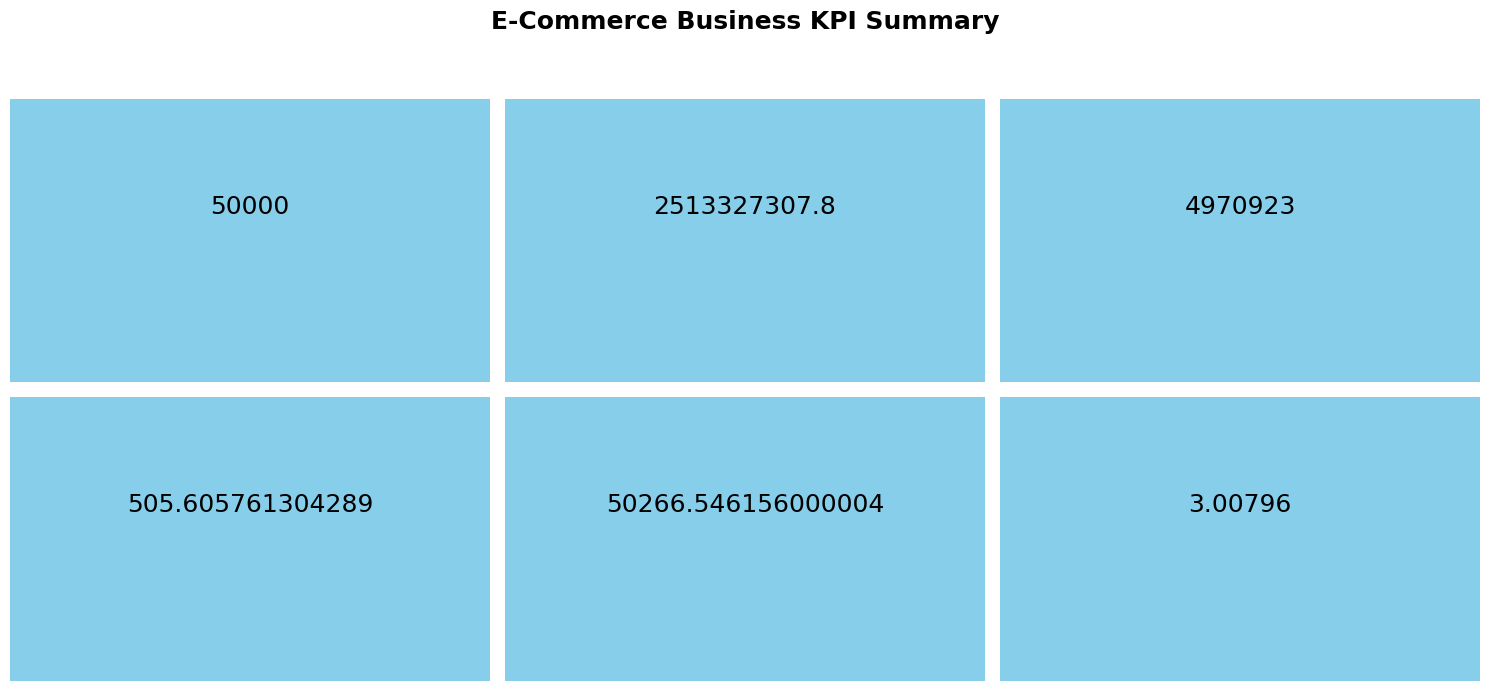

In [69]:
total_customers = df['customer_id'].nunique()
total_revenue = df['total_spent_usd'].sum()
total_purchases = df['total_purchases'].sum()

average_order_value = (total_revenue / total_purchases 
                       if total_purchases != 0 else 0)

average_customer_spending = df['total_spent_usd'].mean()

average_satisfaction = df['satisfaction_score'].mean()

kpis = {
    "Total Customers" : total_customers,
    "Total Revenue" : total_revenue,
    "Total Purchases" : total_purchases,
    "Arg Order Value" : average_order_value,
    "Avg Customer Spending" : average_customer_spending,
    "Avg Satisfaction" : average_satisfaction}


fig, axes = plt.subplots(2,3, figsize = (15,7))

axes = axes.flatten()

for ax, (title, value) in zip(axes, kpis.items()):
    ax.set_facecolor("skyblue")

    ax.text(0.5, 0.62, value,
            ha = 'center',
            va = 'center',
            fontsize = 18)

    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle("E-Commerce Business KPI Summary",
             fontsize = 18,
             fontweight = 'bold')

plt.tight_layout(rect = [0,0,1,0.93])
plt.show()

## 9. Spending distribution chart

The histogram shows how many customers fall within spending ranges; the KDE curve is a smoothed estimate of the distribution. A long right tail would suggest a small number of high-spending customers, but check the rendered plot rather than assuming that shape. The chart is useful for judging skew and whether a log scale or percentile summary may help.

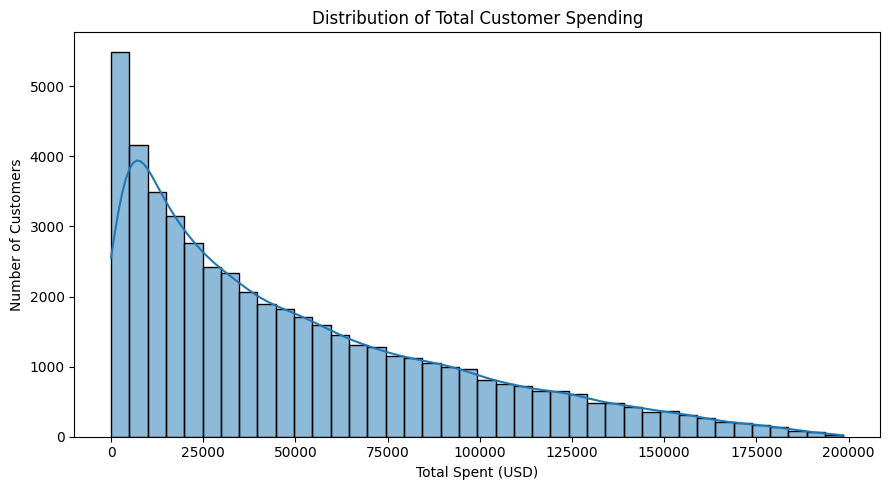

In [70]:
plt.figure(figsize = (9,5))

sb.histplot(
    data = df,
    x = 'total_spent_usd',
    bins = 40,
    kde = True)

plt.title("Distribution of Total Customer Spending")
plt.xlabel("Total Spent (USD)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### Revenue by customer value segment

This bar chart compares the sum of customer spending across the value segments. Because the segments are themselves defined using spending, a higher-spending segment will generally be expected to contribute more revenue; the chart quantifies contribution but does not independently validate the segmentation method.

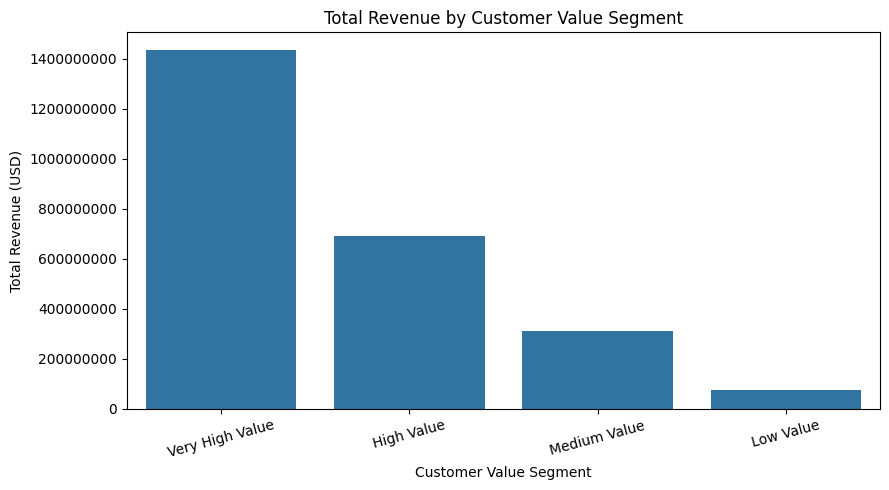

In [71]:
revenue_by_segment = (
    df.groupby("customer_value_segment",observed = True)['total_spent_usd'].sum().sort_values(ascending = False))

plt.figure(figsize = (9,5))

sb.barplot(x = revenue_by_segment.index.astype(str),
           y = revenue_by_segment.values)

plt.title('Total Revenue by Customer Value Segment')
plt.xlabel('Customer Value Segment')
plt.ylabel("Total Revenue (USD)")
plt.xticks(rotation =15)
plt.ticklabel_format(axis = 'y', style = 'plain')
plt.tight_layout()
plt.show()

## 10. Dashboard 1 — customer profile and value

This dashboard combines demographic distribution and categorical summaries. Histograms are appropriate for numeric distributions, while bars are useful for ranking countries and categories. The pie/donut alternatives for customer value, purchase frequency, and loyalty tier emphasize composition; use the labels and percentages to compare shares, and prefer bars when precise category ranking is the main task.

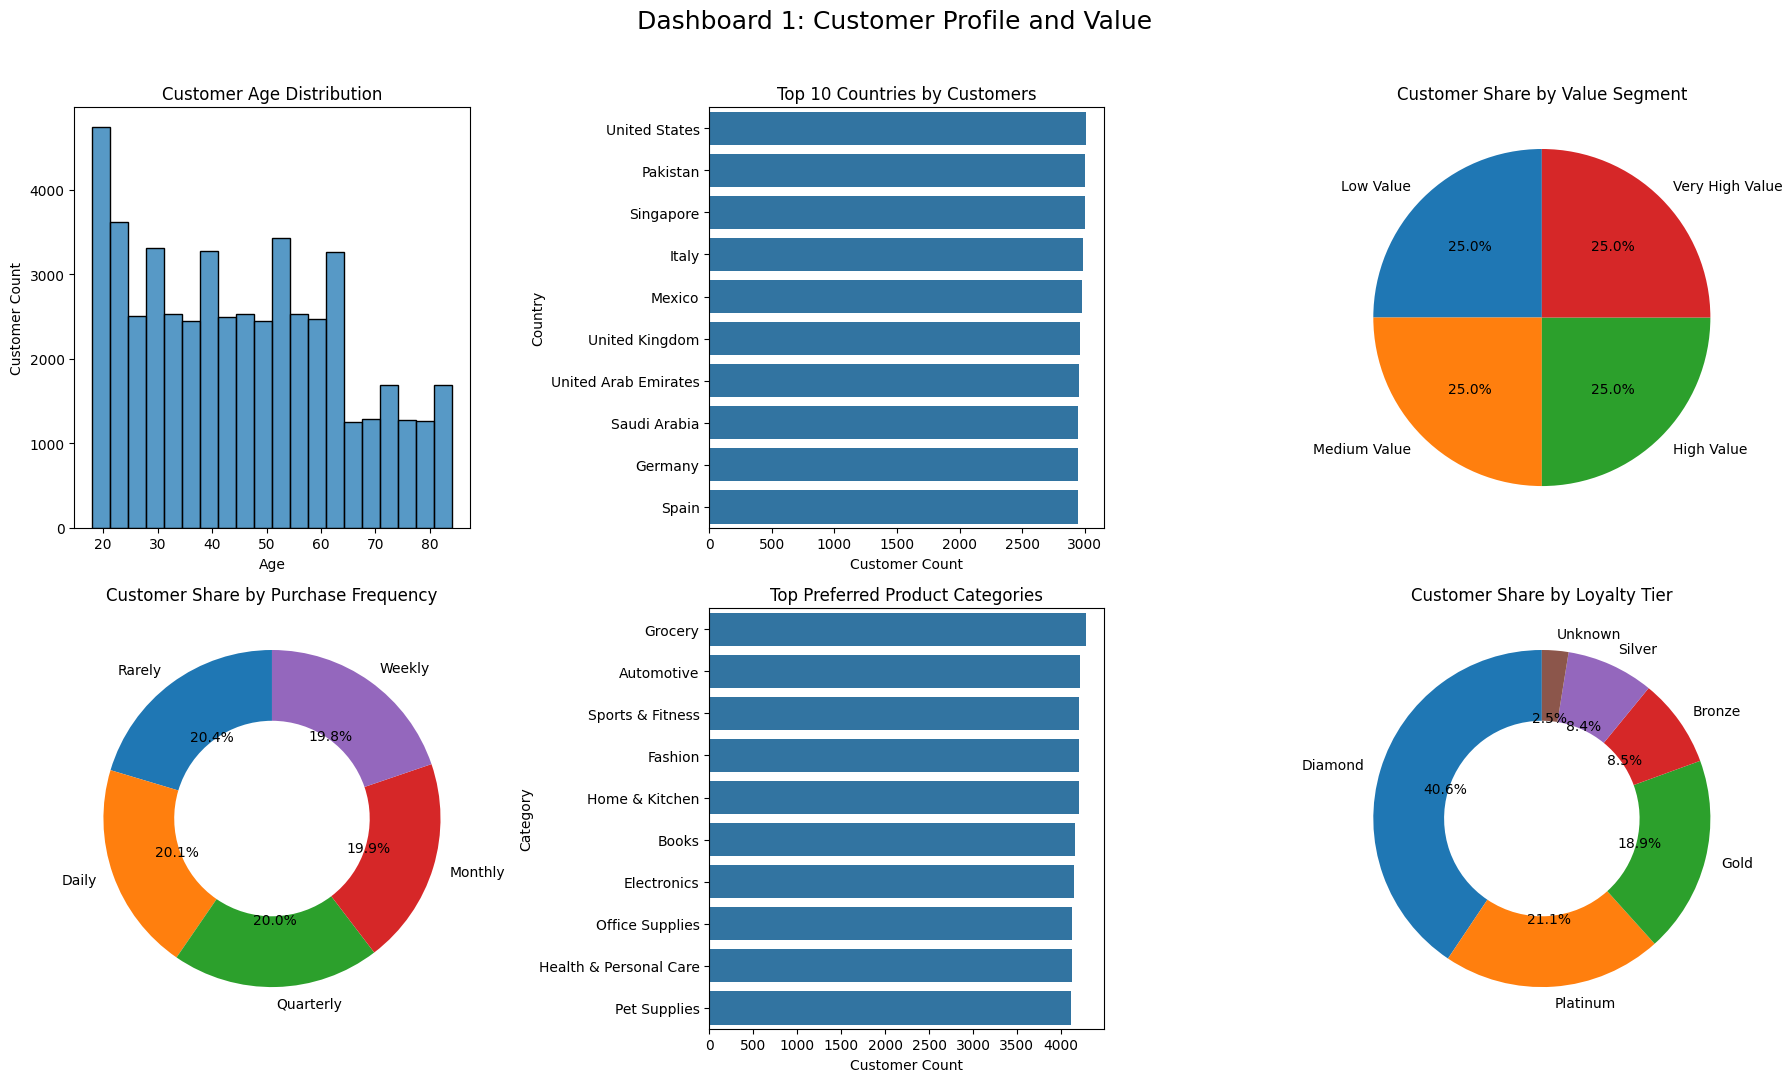

In [72]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

# 1. Age distribution
sb.histplot(data=df, x="age", bins=20, ax=axes[0])
axes[0].set_title("Customer Age Distribution")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Customer Count")

# 2. Top 10 countries by customer count
country_counts = df["country"].value_counts().head(10)
sb.barplot(
    x=country_counts.values,
    y=country_counts.index,
    ax=axes[1]
)
axes[1].set_title("Top 10 Countries by Customers")
axes[1].set_xlabel("Customer Count")
axes[1].set_ylabel("Country")

# 3. Customer share by value segment (pie chart)
segment_order = ["Low Value", "Medium Value", "High Value", "Very High Value"]
segment_counts = df["customer_value_segment"].value_counts().reindex(segment_order).dropna()
segment_counts = segment_counts[segment_counts > 0]
axes[2].pie(
    segment_counts.values,
    labels=segment_counts.index.astype(str),
    autopct="%1.1f%%",
    startangle=90
)
axes[2].set_title("Customer Share by Value Segment")
axes[2].axis("equal")

# 4. Purchase frequency (donut chart)
frequency_counts = df["purchase_frequency"].fillna("Unknown").value_counts()
axes[3].pie(
    frequency_counts.values,
    labels=frequency_counts.index.astype(str),
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.42}
)
axes[3].set_title("Customer Share by Purchase Frequency")
axes[3].axis("equal")

# 5. Top 10 preferred categories
category_counts = df["preferred_category_1"].value_counts().head(10)
sb.barplot(
    x=category_counts.values,
    y=category_counts.index,
    ax=axes[4]
)
axes[4].set_title("Top Preferred Product Categories")
axes[4].set_xlabel("Customer Count")
axes[4].set_ylabel("Category")

# 6. Loyalty tier distribution (donut chart)
loyalty_counts = df["loyalty_tier"].fillna("Unknown").value_counts()
axes[5].pie(
    loyalty_counts.values,
    labels=loyalty_counts.index.astype(str),
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.42}
)
axes[5].set_title("Customer Share by Loyalty Tier")
axes[5].axis("equal")

fig.suptitle("Dashboard 1: Customer Profile and Value", fontsize=18)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## 11. Dashboard 2 — engagement and retention

This dashboard emphasizes recency, engagement, satisfaction, return/complaint rates, and channel revenue. Pie/donut charts communicate part-to-whole shares for discrete groups. Boxplots retain information about spread and outliers, which a single line or average would hide. Treat associations between satisfaction, complaints, returns, and engagement as descriptive rather than causal.

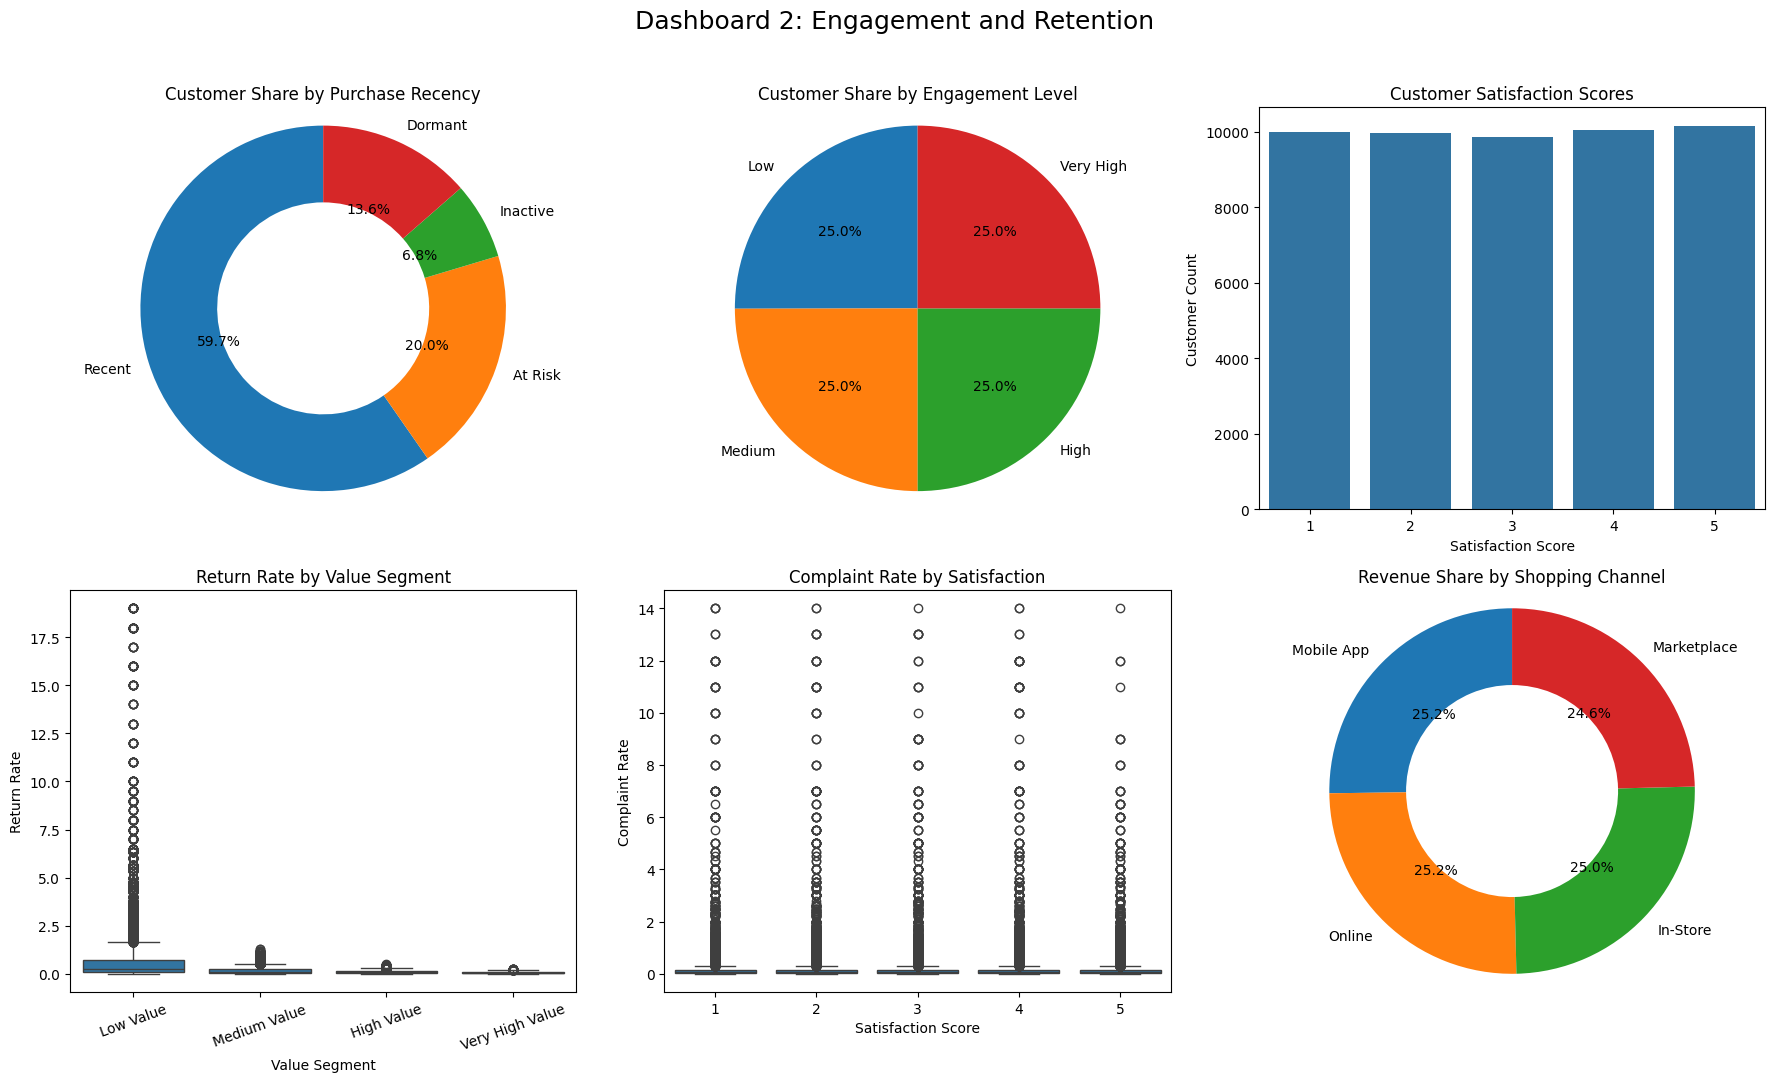

In [73]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

# 1. Recency group distribution (donut chart)
recency_order = ["Recent", "At Risk", "Inactive", "Dormant"]
recency_counts = df["recency_group"].value_counts().reindex(recency_order).dropna()
recency_counts = recency_counts[recency_counts > 0]
axes[0].pie(
    recency_counts.values,
    labels=recency_counts.index.astype(str),
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.42}
)
axes[0].set_title("Customer Share by Purchase Recency")
axes[0].axis("equal")

# 2. Engagement level distribution (pie chart)
engagement_order = ["Low", "Medium", "High", "Very High"]
engagement_counts = df["engagement_level"].value_counts().reindex(engagement_order).dropna()
engagement_counts = engagement_counts[engagement_counts > 0]
axes[1].pie(
    engagement_counts.values,
    labels=engagement_counts.index.astype(str),
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("Customer Share by Engagement Level")
axes[1].axis("equal")

# 3. Satisfaction distribution
sb.countplot(
    data=df,
    x="satisfaction_score",
    ax=axes[2]
)
axes[2].set_title("Customer Satisfaction Scores")
axes[2].set_xlabel("Satisfaction Score")
axes[2].set_ylabel("Customer Count")

# 4. Return rate by customer value segment
sb.boxplot(
    data=df,
    x="customer_value_segment",
    y="return_rate",
    order=["Low Value", "Medium Value", "High Value", "Very High Value"],
    ax=axes[3]
)
axes[3].set_title("Return Rate by Value Segment")
axes[3].set_xlabel("Value Segment")
axes[3].set_ylabel("Return Rate")
axes[3].tick_params(axis="x", rotation=20)

# 5. Complaint rate by satisfaction score
sb.boxplot(
    data=df,
    x="satisfaction_score",
    y="complaint_rate",
    ax=axes[4]
)
axes[4].set_title("Complaint Rate by Satisfaction")
axes[4].set_xlabel("Satisfaction Score")
axes[4].set_ylabel("Complaint Rate")

# 6. Revenue by shopping channel
channel_revenue = (
    df.groupby("shopping_channel")["total_spent_usd"]
    .sum()
    .sort_values(ascending=False)
)
# Donut chart emphasizes each channel's share of total revenue.
channel_revenue = channel_revenue[channel_revenue > 0]
axes[5].pie(
    channel_revenue.values,
    labels=channel_revenue.index.astype(str),
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.42}
)
axes[5].set_title("Revenue Share by Shopping Channel")
axes[5].axis("equal")

fig.suptitle("Dashboard 2: Engagement and Retention", fontsize=18)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### Dashboard output check

If this cell is blank, it is a spacer and does not affect the analysis. The next section adds written interpretation guidance and standalone charts.

## Insights and Interpretation Guide

> **Important:** The notes below describe how to interpret the charts. Confirm the actual patterns in the rendered plots before presenting them as findings; no numerical conclusions are assumed here.

### Business KPI summary
- **Total customers** shows the size of the customer base; compare it across future reporting periods to assess growth.
- **Total revenue** and **total purchases** indicate overall business scale. They do not, by themselves, show profitability.
- **Average order value (AOV)** is revenue divided by purchases in this notebook. Check that this matches your business definition of an order.
- **Average customer spending** can be affected by a small number of very high-spending customers, so read it alongside the spending distribution.
- **Average satisfaction** is easier to interpret when paired with the full satisfaction-score distribution.

### Spending distribution
- A right-skewed histogram would indicate that many customers spend relatively little while a smaller group spends much more.
- A long right tail suggests checking high-spending observations, but high values are not automatically errors.
- The KDE curve is a smoothed estimate of the distribution; treat it as a guide rather than observed data.

### Customer value and profile
- Compare **customer count** with **revenue contribution** by value segment. A segment with fewer customers may still generate a large share of revenue.
- Country and preferred-category charts show where customers are concentrated; they do not explain why those customers behave that way.
- Loyalty-tier and purchase-frequency charts can help identify the dominant groups and potential retention opportunities.

### Engagement and retention
- Recency groups help distinguish recently active customers from customers who may need re-engagement. Check the group definitions and cut-off boundaries before acting on them.
- Compare engagement levels with satisfaction, complaint rate, and return rate to look for possible relationships. These are associations, not proof of causation.
- Boxplots show medians, spread, and potential outliers; compare the median and interquartile range rather than relying only on the mean.
- Revenue by shopping channel measures revenue contribution, not channel profitability or marketing effectiveness.

### Data and methodology caveats
- The notebook creates `calculated_spent` from `total_purchases * avg_order_value_usd`; compare it with `total_spent_usd` before treating the two as interchangeable.
- Rate calculations that divide by `total_purchases` can produce undefined values when purchases are zero. Review missing/infinite results before interpreting those rates.
- `pd.qcut` creates quantile-based groups, so segment boundaries depend on this dataset. The groups may not represent fixed business thresholds.
- The `recency_score` currently assigns integer labels to quantile bins. Confirm that the score direction matches your intended scoring logic: depending on bin ordering, a larger number may represent greater recency in days rather than more recent activity.
- Segment labels are engineered rules, not ground-truth customer types. Validate them against business outcomes before using them for targeting.

## 12. Additional standalone charts

These supplementary charts give alternative views beyond the dashboards. Use them to answer a specific question rather than adding chart types only for variety; each plot should communicate a distinct comparison or relationship.

## Additional charts

The following cells are appended after the existing code. They do not modify the original cells. Run them after the notebook has created `df` and the derived columns.

### Line chart — average spending by age group

This compares mean spend across ordered age bands. The connecting line helps the eye compare adjacent groups, but the x-axis is age categories rather than time, so do not describe it as a time trend. Read alongside group sizes because averages from small groups can be unstable.

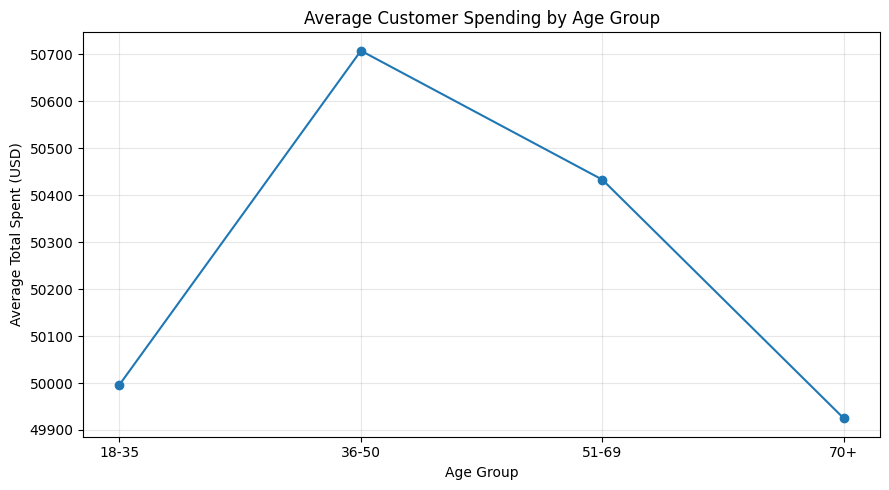

In [74]:
# 1. Line chart: average spending across age groups
# A line connects ordered groups for visual comparison; it does not imply a time series.
age_spending = (
    df.groupby("age_group", observed=True)["total_spent_usd"]
      .mean()
      .reindex(["18-35", "36-50", "51-69", "70+"])
      .dropna()
)

plt.figure(figsize=(9, 5))
plt.plot(age_spending.index.astype(str), age_spending.values, marker="o")
plt.title("Average Customer Spending by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Total Spent (USD)")
plt.ticklabel_format(axis="y", style="plain")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Pie chart — share of customers by value segment

This shows the percentage of customers in each spending-based segment. It answers a composition question, not which segment generates the most revenue; use the revenue-by-segment bar chart for the latter.

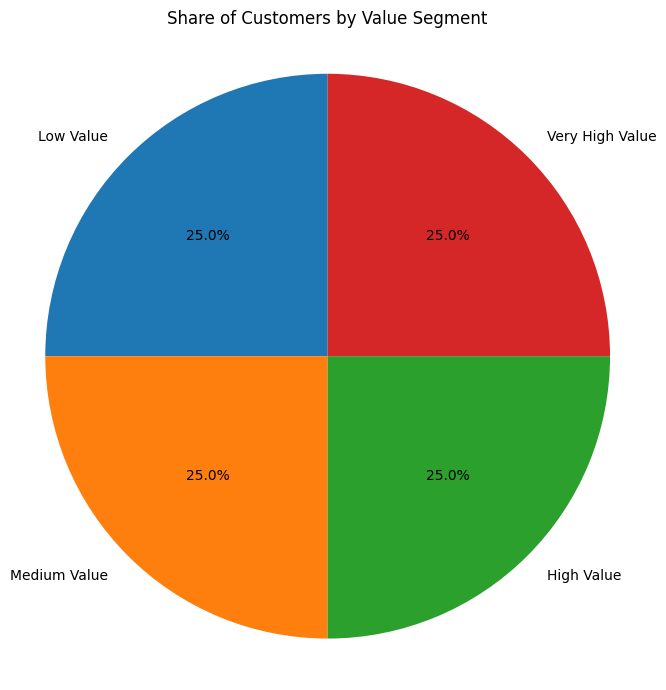

In [75]:
# 2. Pie chart: customer share by value segment
segment_counts = df["customer_value_segment"].value_counts().reindex(
    ["Low Value", "Medium Value", "High Value", "Very High Value"]
).dropna()

plt.figure(figsize=(7, 7))
plt.pie(
    segment_counts.values,
    labels=segment_counts.index.astype(str),
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Share of Customers by Value Segment")
plt.axis("equal")
plt.tight_layout()
plt.show()

### Donut chart — share by loyalty tier

The donut shows how the customer base is divided among recorded loyalty tiers, including `Unknown` if present. Many tiny slices can make comparisons difficult; a sorted bar chart is preferable when there are many tiers.

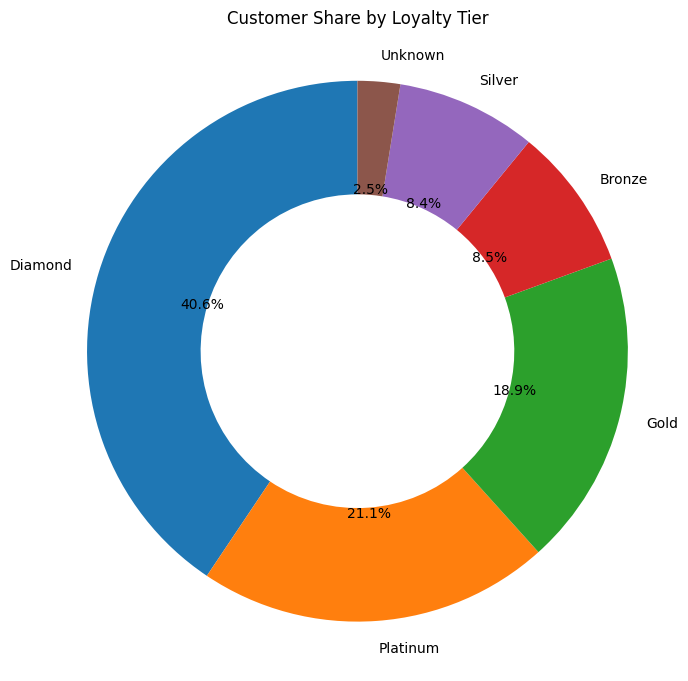

In [76]:
# 3. Donut chart: customer share by loyalty tier
loyalty_counts = df["loyalty_tier"].fillna("Unknown").value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    loyalty_counts.values,
    labels=loyalty_counts.index.astype(str),
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.42}
)
plt.title("Customer Share by Loyalty Tier")
plt.axis("equal")
plt.tight_layout()
plt.show()

### Scatter plot — spending versus purchase count

Each point represents a customer and compares total purchases with total spending, colored by value segment. A positive association would be consistent with frequent purchasers spending more overall, but customers with similar purchase counts can differ due to average order value. Overplotting may hide dense areas, so consider transparency or aggregation when interpreting the plot.

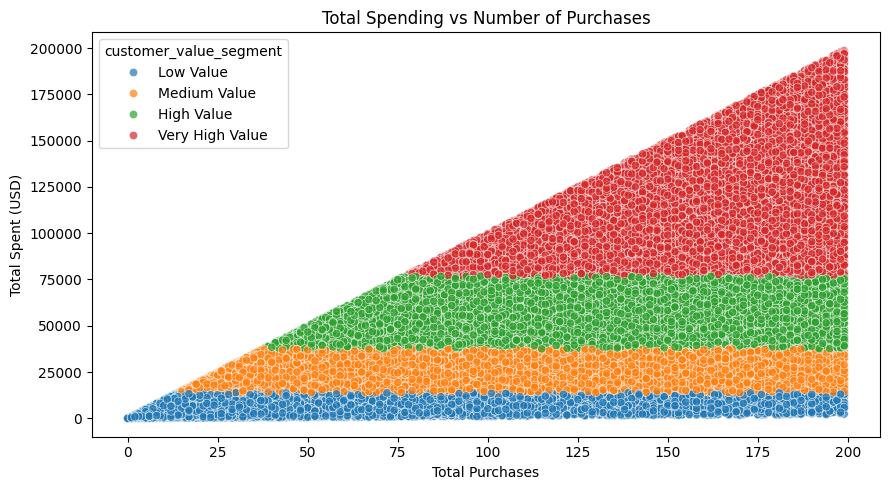

In [77]:
# 4. Scatter plot: total spending vs total purchases
# Useful for spotting customers with high purchase counts but relatively low/high spend.
plt.figure(figsize=(9, 5))
sb.scatterplot(
    data=df,
    x="total_purchases",
    y="total_spent_usd",
    hue="customer_value_segment",
    alpha=0.7
)
plt.title("Total Spending vs Number of Purchases")
plt.xlabel("Total Purchases")
plt.ylabel("Total Spent (USD)")
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()